In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("altruistdelhite04/loan-prediction-problem-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'loan-prediction-problem-dataset' dataset.
Path to dataset files: /kaggle/input/loan-prediction-problem-dataset


In [6]:
import os
os.listdir(path)

['test_Y3wMUE5_7gLdaTN.csv', 'train_u6lujuX_CVtuZ9i.csv']

In [7]:
df = pd.read_csv(path + "/train_u6lujuX_CVtuZ9i.csv")

In [10]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [12]:
df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [13]:
df.select_dtypes(include=np.number).columns

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='object')

In [14]:
df.select_dtypes(include='object').columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [15]:
df['Loan_Status'].value_counts()

,count
Loan_Status,
Y,422
N,192


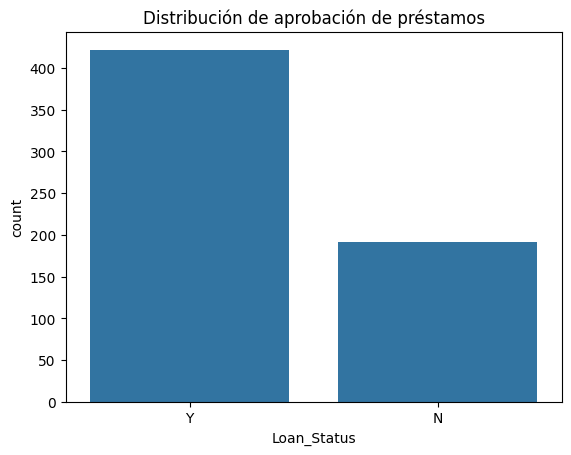

In [16]:
sns.countplot(x='Loan_Status', data=df)
plt.title("Distribución de aprobación de préstamos")
plt.show()

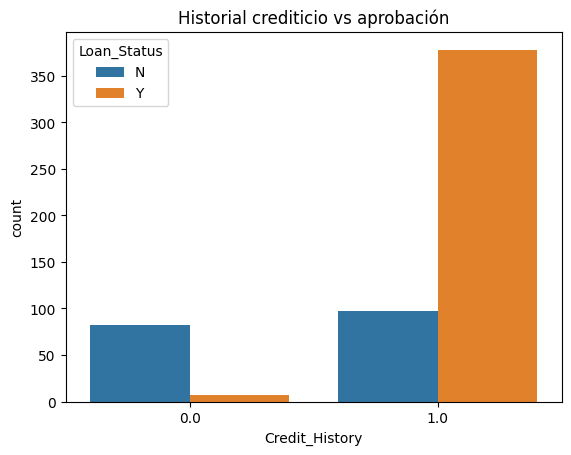

In [17]:
sns.countplot(
    x='Credit_History',
    hue='Loan_Status',
    data=df
)

plt.title("Historial crediticio vs aprobación")
plt.show()

In [18]:

## las categoricas la rellenamos con la moda

for col in ['Gender','Married','Dependents','Self_Employed']:
    df[col].fillna(df[col].mode()[0], inplace=True)

/tmp/ipykernel_6602/3789419656.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


In [19]:
## las numericas con la mediana

df['LoanAmount'].fillna(df['LoanAmount'].median(), inplace=True)

df['Loan_Amount_Term'].fillna(
    df['Loan_Amount_Term'].median(),
    inplace=True
)

df['Credit_History'].fillna(
    df['Credit_History'].median(),
    inplace=True
)

/tmp/ipykernel_6602/1417591614.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['LoanAmount'].fillna(df['LoanAmount'].median(), inplace=True)
/tmp/ipykernel_6602/1417591614.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inpl

In [20]:
#Transformamos texto a números.
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

In [21]:
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

In [22]:
X = df.drop('Loan_Status', axis=1)

In [23]:
y = df['Loan_Status']

In [24]:
from sklearn.model_selection import train_test_split

In [25]:
##80% entrenamiento
##20% prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [26]:
## Modelo Árbol de decisión
from sklearn.tree import DecisionTreeClassifier

In [27]:
tree = DecisionTreeClassifier(
    random_state=42
)

tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [28]:
y_pred_tree = tree.predict(X_test)

In [29]:
## Modelo Random Forest
from sklearn.ensemble import RandomForestClassifier

In [30]:
rf = RandomForestClassifier(
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [31]:
y_pred_rf = rf.predict(X_test)

In [32]:
##Evaluacion
from sklearn.metrics import accuracy_score

In [33]:
accuracy_score(y_test, y_pred_rf)

0.7804878048780488

In [34]:
##De todos los préstamos que predije como aprobados, ¿cuántos realmente eran aprobados?
from sklearn.metrics import precision_score

precision_score(y_test, y_pred_rf)

0.7572815533980582

In [35]:
## De todos los préstamos aprobados, ¿cuántos encontré?
from sklearn.metrics import recall_score

recall_score(y_test, y_pred_rf)

0.975

In [36]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

           0       0.90      0.42      0.57        43
           1       0.76      0.97      0.85        80

    accuracy                           0.78       123
   macro avg       0.83      0.70      0.71       123
weighted avg       0.81      0.78      0.75       123



In [37]:
## Matriz de confusión
from sklearn.metrics import confusion_matrix

In [38]:
cm = confusion_matrix(
    y_test,
    y_pred_rf
)

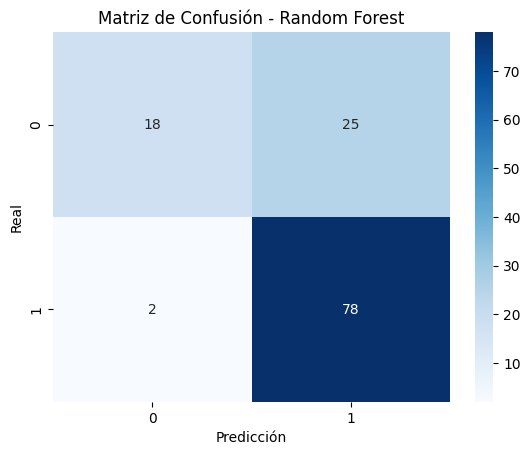

In [52]:
# Matriz de confusión Random Forest

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Matriz de Confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

# 18 fueron Rechazados
# 78 fueron aprovados
# 25 fueron errores
# 2 fueron errores

In [40]:
from sklearn.metrics import f1_score

print("F1 Score:", f1_score(y_test, y_pred_rf))

F1 Score: 0.8524590163934426


In [41]:
# Evaluación Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Accuracy: 0.7804878048780488
Precision: 0.7572815533980582
Recall: 0.975
F1 Score: 0.8524590163934426


In [42]:
print("\n=== REPORTE COMPLETO ===")
print(classification_report(y_test, y_pred_rf))


=== REPORTE COMPLETO ===
              precision    recall  f1-score   support

           0       0.90      0.42      0.57        43
           1       0.76      0.97      0.85        80

    accuracy                           0.78       123
   macro avg       0.83      0.70      0.71       123
weighted avg       0.81      0.78      0.75       123



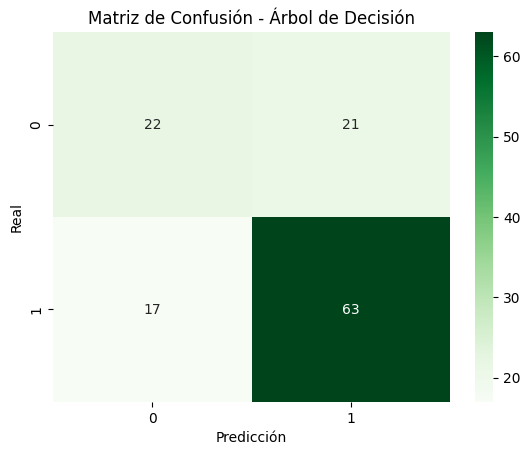

In [53]:
# Matriz de confusión Árbol de Decisión

cm_tree = confusion_matrix(
    y_test,
    y_pred_tree
)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Matriz de Confusión - Árbol de Decisión")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

22 fueron Rechazados
63 fueron aprovados
17 fueron errores
21 fueron errores

In [50]:
## comparamos
print("Accuracy Árbol de Decisión:",
      accuracy_score(y_test, y_pred_tree))

print("Accuracy Random Forest:",
      accuracy_score(y_test, y_pred_rf))

Accuracy Árbol de Decisión: 0.6910569105691057
Accuracy Random Forest: 0.7804878048780488


In [51]:
#¿Qué variable parece influir más en la predicción?

importances = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': rf.feature_importances_
})

importances = importances.sort_values(
    by='Importancia',
    ascending=False
)

print(importances)

             Variable  Importancia
10     Credit_History     0.245658
6     ApplicantIncome     0.154094
0             Loan_ID     0.152056
8          LoanAmount     0.151248
7   CoapplicantIncome     0.086406
9    Loan_Amount_Term     0.047681
11      Property_Area     0.047121
3          Dependents     0.039856
2             Married     0.022624
4           Education     0.020818
1              Gender     0.017540
5       Self_Employed     0.014899


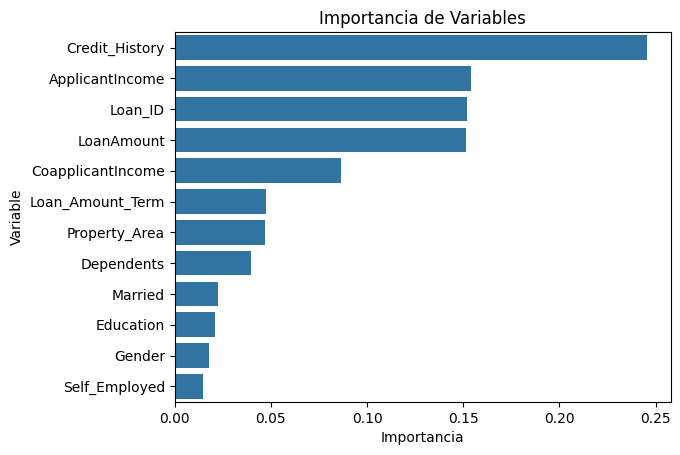

In [48]:
sns.barplot(
    data=importances,
    x='Importancia',
    y='Variable'
)

plt.title("Importancia de Variables")
plt.show()

¿Qué tan bueno es el modelo?

El modelo Random Forest obtuvo una exactitud (Accuracy) de 78.05%, lo que significa que clasificó correctamente aproximadamente 78 de cada 100 solicitudes de préstamo. Además, alcanzó una precisión de 75.73%, un Recall de 97.50% y un F1-Score de 85.25%. Estos resultados indican que el modelo tiene una alta capacidad para identificar préstamos aprobados y presenta un desempeño satisfactorio para la predicción de solicitudes de crédito.

¿Qué variable parece influir más en la predicción?

La variable que presentó mayor influencia en la predicción fue Credit_History, lo que indica que el historial crediticio del solicitante es el factor más importante para determinar la aprobación de un préstamo. Otras variables relevantes fueron ApplicantIncome, Loan_ID y LoanAmount, aunque con una importancia menor en comparación con el historial crediticio.